In [1]:

import multiprocessing

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from scipy.optimize import curve_fit
from scipy.stats import norm
from pytensor.tensor import erf

In [2]:
# ============================================================
# ENERGY RESOLUTION
# ============================================================
def sigma_fun(E):

    A = 3.68436e1
    B = 1.72714e4

    return (
        E * pt.sqrt(A/E + B/E**2)
        / 2.355
        / 100
    )
    


In [3]:

# ============================================================
# DATA LOADING
# ============================================================
def load_spectrum(file_path, calibration, energy_range=(0, 3000)):
    """
    Load raw spectrum and convert channels to energy.
    """

    data = pd.read_csv(file_path, header=None)
    spectrum = data[0].to_numpy(dtype=np.float64)

    channels = np.arange(len(spectrum))

    E = (
        channels * calibration["a"]
        + calibration["b"]
        + calibration["c"] * channels**2
    )

    mask = (E >= energy_range[0]) & (E <= energy_range[1])

    return E[mask], spectrum[mask]

In [4]:
# ============================================================
# HISTOGRAMMING
# ============================================================
def make_histogram(E, spectrum, bins):
    counts, edges = np.histogram(E, bins=bins, weights=spectrum)
    centers = 0.5 * (edges[1:] + edges[:-1])

    return centers, counts



In [5]:

# ============================================================
# GAUSSIAN MODEL
# ============================================================
def gaussian_plus_bg(E, mu, sigma, area, background):
    """
    Gaussian normalized to total area + flat background.
    """

    gaussian = (
        area
        / (sigma * np.sqrt(2 * np.pi))
        * np.exp(-0.5 * ((E - mu) / sigma) ** 2)
    )

    return gaussian + background


In [6]:
# ============================================================
# PEAK FITTING
# ============================================================
def fit_peak(E, counts, center, window=4, plot=True):
    """
    Fit a Gaussian peak + constant background.
    """

    mask = (E > center - window) & (E < center + window)

    E_roi = E[mask]
    counts_roi = counts[mask]

    sigma_guess = sigma_fun(center)

    p0 = [
        center,
        sigma_guess,
        np.sum(counts_roi),
        np.median(counts_roi),
    ]

    bounds = (
        [center - 1, 0.01, 0, 0],
        [center + 1, 10, np.inf, np.inf],
    )

    popt, pcov = curve_fit(
        gaussian_plus_bg,
        E_roi,
        counts_roi,
        p0=p0,
        bounds=bounds,
        #sigma=np.sqrt(counts_roi),
        maxfev=10000,
    )

    perr = np.sqrt(np.diag(pcov))

    result = {
        "mu": popt[0],
        "sigma": popt[1],
        "N": popt[2],
        "B": popt[3],
        "err_mu": perr[0],
        "err_sigma": perr[1],
        "err_N": perr[2],
        "err_B": perr[3],
    }

    if plot:
        fig, ax = plt.subplots(
            2,
            1,
            figsize=(7, 6),
            sharex=True,
            gridspec_kw={"height_ratios": [3, 1]},
        )

        E_fit = np.linspace(E_roi.min(), E_roi.max(), 400)
        model_fit = gaussian_plus_bg(E_fit, *popt)

        ax[0].step(E_roi, counts_roi, where="mid", color="black", label="Data")
        ax[0].plot(E_fit, model_fit, color="red", lw=2, label="Fit")

        ax[0].set_ylabel(f"Counts / {E_roi[1]-E_roi[0]:.2f} keV")
        ax[0].set_title(f"Peak @ {center:.2f} keV")
        ax[0].legend()
        ax[0].grid(alpha=0.3)

        residuals = counts_roi - gaussian_plus_bg(E_roi, *popt)

        ax[1].scatter(E_roi, residuals, s=15)
        ax[1].axhline(0, color="red")
        ax[1].set_xlabel("Energy [keV]")
        ax[1].set_ylabel("Residuals")
        ax[1].grid(alpha=0.3)

        plt.tight_layout()
        plt.show()

    return result


In [7]:

# ============================================================
# BUILD TOTAL DATASET
# ============================================================
def build_total_spectrum(files_config, bins):
    all_histograms = []
    total_time = 0

    for key, cfg in files_config.items():
        E, spectrum = load_spectrum(
            cfg["path"],
            cfg["calibration"],
            ENERGY_RANGE,
        )

        E_centers, counts = make_histogram(E, spectrum, bins)

        all_histograms.append(counts)
        total_time += cfg["time"]

    total_counts = np.sum(all_histograms, axis=0)

    return E_centers, total_counts, total_time

In [8]:
FILES = {
    "50d": {
        "path": "csv-files/zro2_white&green_ 50_days.csv",
        "time": 4279386,
        "calibration": {
            "a": 0.357304,
            "b": -0.295444,
            "c": 1.352297e-9,
        },
    },
    "90d": {
        "path": "csv-files/90_days.csv",
        "time": 7550023,
        "calibration": {
            "a": 1.2696e-01,
            "b": 4.179423e-01,
            "c": 1.514025e-08,
        },
    },
}

In [9]:
ENERGY_RANGE = (0, 3000)
BIN_WIDTH = 0.4



In [10]:
# ============================================================
# MAIN DATA PREPARATION
# ============================================================
BINS = np.arange(
    ENERGY_RANGE[0],
    ENERGY_RANGE[1] + BIN_WIDTH,
    BIN_WIDTH
)

E_tot, Ntot, t_tot = build_total_spectrum(FILES, BINS)

print(
    f"Total counts = {np.sum(Ntot):.0f} "
    f"in {t_tot / (60 * 60 * 24):.1f} days"
)


Total counts = 42055 in 136.9 days


In [11]:
sigma_fun(776.5).eval()

array(0.9095424)

Text(0, 0.5, 'Counts / 0.40 keV')

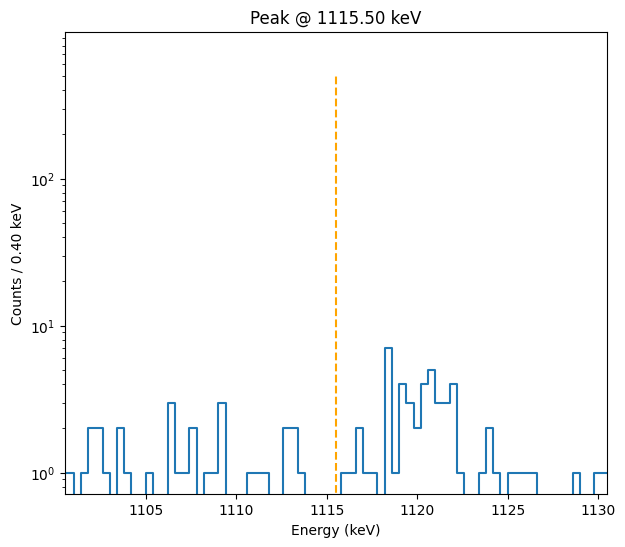

In [42]:
plt.figure(figsize=(7, 6))
plt.step(
    E_tot,
    #bins=BINS,
    Ntot,
    #histtype="step",
)

plt.vlines(2614, 1,200, color = 'red')
plt.vlines(511, 1,200, color = 'red')
peak = 1115.5
de = 15
#plt.xlim(0,3000)
plt.xlim(peak-de, peak+de)
plt.vlines(peak, 0,500, color = 'orange', ls = '--')
plt.title(f"Peak @ {peak:.2f} keV")
plt.yscale("log")
plt.xlabel("Energy (keV)")
plt.ylabel(f"Counts / {BINS[1]-BINS[0]:.2f} keV")

In [35]:
# ============================================================
# PEAK FITTING
# ============================================================
def fit_peak(E, counts, center, window=4, plot=True):
    """
    Fit a Gaussian peak + constant background.
    """

    mask = (E > center - window) & (E < center + window)

    E_roi = E[mask]
    counts_roi = counts[mask]

    sigma_guess = float(sigma_fun(center).eval())

    p0 = [
        center,
        sigma_guess,
        np.sum(counts_roi),
        0,
    ]

    bounds = (
        [center - 0.5, sigma_guess*0.9, 0, 0],
        [center + 0.5, sigma_guess*1.1,np.sum(counts_roi)*3, np.inf],
    )

    sigma_counts = np.sqrt(np.maximum(counts_roi, 1))

    popt, pcov = curve_fit(
                        gaussian_plus_bg,
                        E_roi,
                        counts_roi,
                        p0=p0,
                        bounds=bounds,
                        sigma=sigma_counts,
                        absolute_sigma=True,
                        maxfev=10000,
                    )

    perr = np.sqrt(np.diag(pcov))

    result = {
        "mu": popt[0],
        "sigma": popt[1],
        "N": popt[2],
        "B": popt[3],
        "err_mu": perr[0],
        "err_sigma": perr[1],
        "err_N": perr[2],
        "err_B": perr[3],
    }

    if plot:
        fig, ax = plt.subplots(
            2,
            1,
            figsize=(7, 6),
            sharex=True,
            gridspec_kw={"height_ratios": [3, 1]},
        )

        E_fit = np.linspace(E_roi.min(), E_roi.max(), 400)
        model_fit = gaussian_plus_bg(E_fit, *popt)

        ax[0].step(E_roi, counts_roi, where="mid", color="black", label="Data")
        ax[0].plot(E_fit, model_fit, color="red", lw=2, label="Fit")

        ax[0].set_ylabel(f"Counts / {E_roi[1]-E_roi[0]:.2f} keV")
        ax[0].set_title(f"Peak @ {center:.2f} keV")
        ax[0].legend()
        ax[0].grid(alpha=0.3)

        residuals = counts_roi - gaussian_plus_bg(E_roi, *popt)

        ax[1].scatter(E_roi, residuals, s=15)
        ax[1].axhline(0, color="red")
        ax[1].set_xlabel("Energy [keV]")
        ax[1].set_ylabel("Residuals")
        ax[1].grid(alpha=0.3)

        plt.tight_layout()
        plt.show()

    return result


In [36]:
print(type(E_tot))
print(type(Ntot))
print(type(sigma_fun(554.3)))

print(sigma_fun(554.3))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'pytensor.tensor.variable.TensorVariable'>
True_div.0


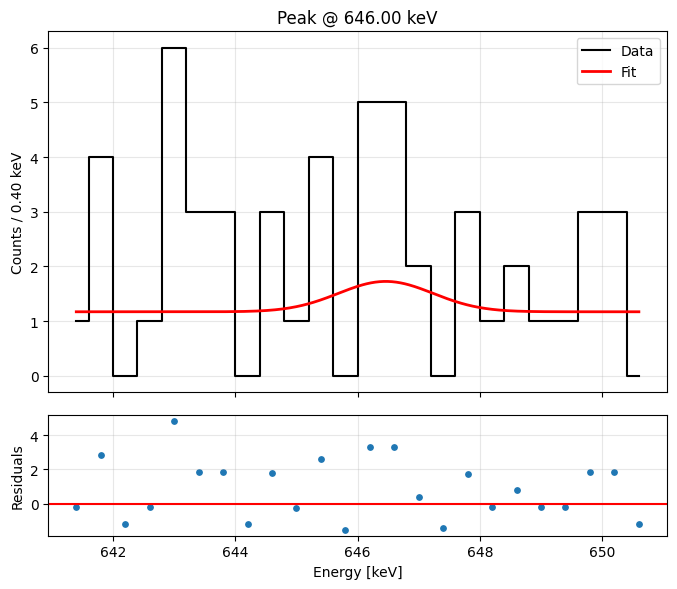

{'mu': np.float64(646.4606181929387),
 'sigma': np.float64(0.7745089782631117),
 'N': np.float64(1.0780096632049183),
 'B': np.float64(1.1717081140340955),
 'err_mu': np.float64(1.31537481577728),
 'err_sigma': np.float64(1.7083745173340439),
 'err_N': np.float64(2.1309544329845056),
 'err_B': np.float64(0.33633590953787945)}

In [39]:
fit_peak(E_tot, Ntot, 646, window=5, plot=True)

Text(0.5, 1.0, 'Region of Interest (ROI) around 871.1 keV 94Zr')

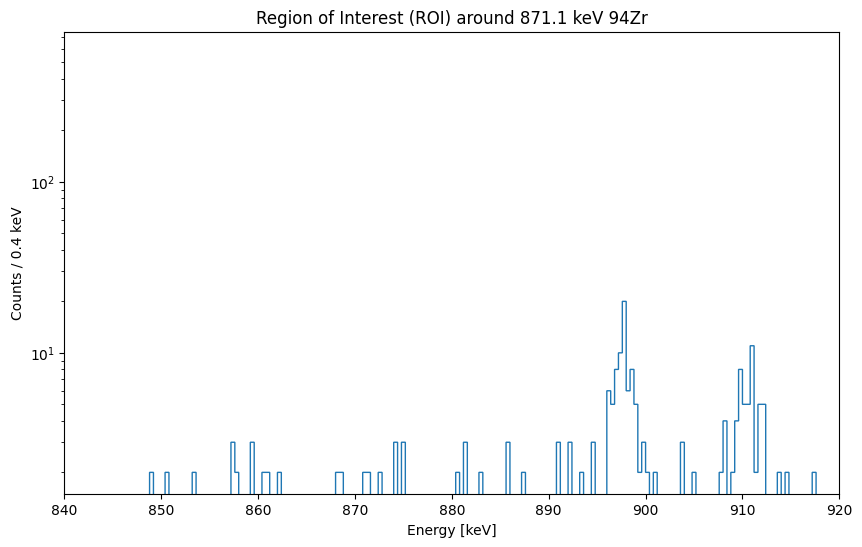

In [38]:
plt.figure(figsize=(10, 6))
plt.hist(
    E_tot,
    bins=BINS,
    weights=Ntot,
    range=(840, 920),
    histtype="step",
)
plt.xlim(840, 920)
plt.ylim(1.5, None)
plt.yscale("log")
plt.ylabel("Counts / 0.4 keV")
plt.xlabel("Energy [keV]")
plt.title("Region of Interest (ROI) around 871.1 keV 94Zr")

Text(0.5, 1.0, 'Region of Interest (ROI) around 96Zr')

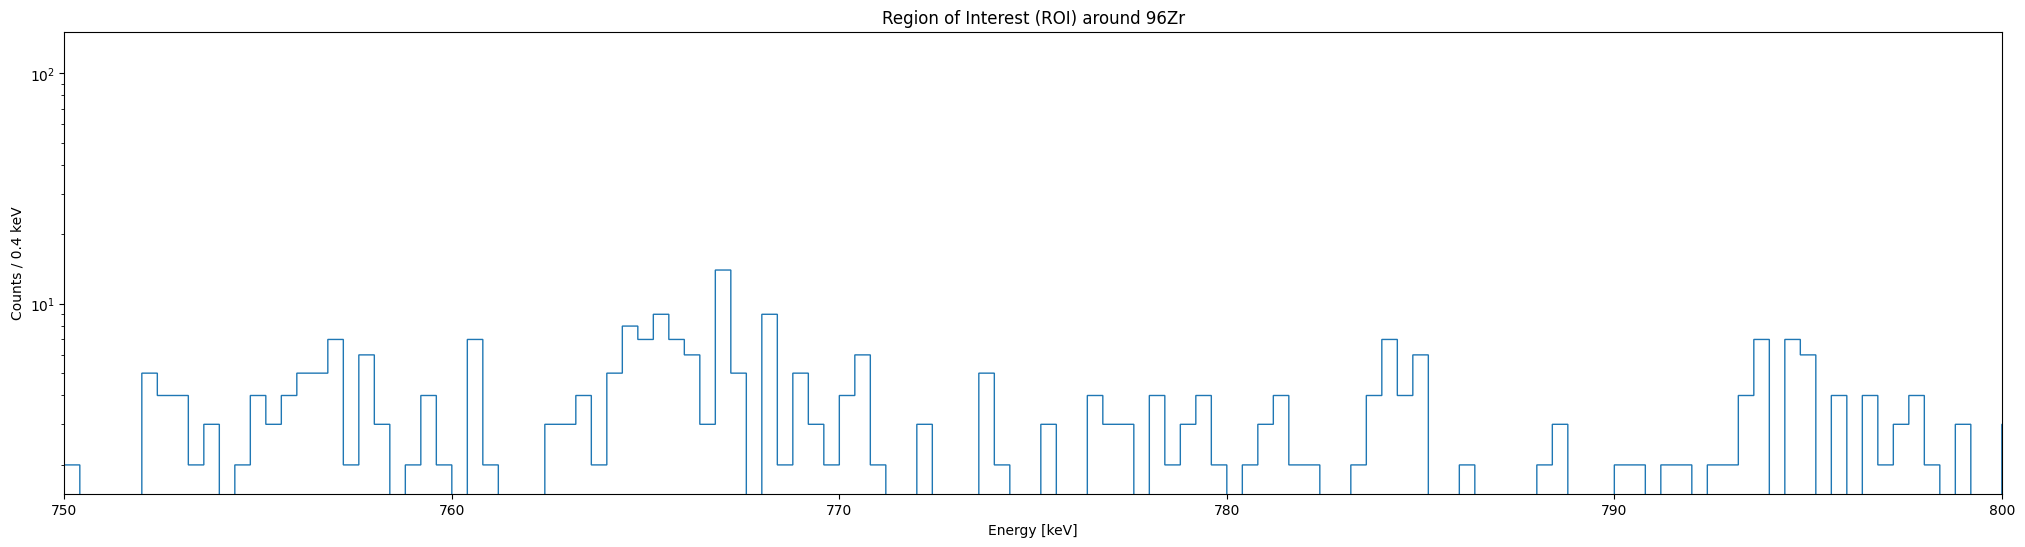

In [ ]:
plt.figure(figsize=(25, 6))
plt.hist(
    E_tot,
    bins=BINS,
    weights=Ntot,
    range=(750, 800),
    histtype="step",
)
plt.xlim(750, 800)
plt.ylim(1.5, None)
plt.yscale("log")
plt.ylabel("Counts / 0.4 keV")
plt.xlabel("Energy [keV]")
plt.title("Region of Interest (ROI) around 96Zr")